# EDA — Matriz de presencia de ASNs

Análisis exploratorio de cómo los ASNs aparecen y desaparecen día a día en la topología de Internet.
Fuente: matriz generada por `graph-analysis/asn-presence.py` a partir de los archivos `unique-asns-YYYYMMDD.txt`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from itertools import combinations

In [2]:
# --- Configuración ---

# PRESENCE_FILE = "../fetch/day-by-day/202504/asn-presence.txt"
PRESENCE_FILE = "../fetch/asn-presence-202504.txt"


# Sección 3: umbral de baja presencia
UMBRAL_BAJA_PRESENCIA = 0.30          # ASNs presentes menos del 30% de los días

# Sección 4: umbral para marcar días con churning anómalo
UMBRAL_CHURN_SIGMA = 2.0              # días con churn > media + N*σ

# Sección 5: clasificación de transiciones — mínimo de transiciones para "flapping"
MIN_TRANSICIONES_FLAP = 4

# Sección 7: twin detection — sólo ASNs con presencia por debajo de este umbral
TWIN_MAX_PRESENCIA = 0.90             # excluye ASNs presentes >= 90% de los días
TWIN_TOP_N = 30                       # pares más similares a mostrar

## 1. Carga y visión general

In [3]:
df = pd.read_csv(PRESENCE_FILE, sep=r"\s+", index_col=0)
df = df.astype(np.int8)  # el índice (ASN) queda como int64; sólo las columnas de datos se comprimen

# Convertir columnas a fechas para facilitar plots
df.columns = pd.to_datetime(df.columns, format="%Y%m%d")

n_asns, n_dias = df.shape
fecha_inicio = df.columns[0].date()
fecha_fin    = df.columns[-1].date()

# Detectar huecos en la secuencia de fechas
fechas_esperadas = pd.date_range(fecha_inicio, fecha_fin, freq="D")
huecos = fechas_esperadas.difference(df.columns)

print(f"ASNs únicos:      {n_asns:,}")
print(f"Días en matriz:   {n_dias}  ({fecha_inicio} → {fecha_fin})")
print(f"Días esperados:   {len(fechas_esperadas)}")
if len(huecos):
    print(f"Huecos detectados: {[str(d.date()) for d in huecos]}")
else:
    print("Sin huecos en la secuencia de fechas.")

ASNs únicos:      85,075
Días en matriz:   30  (2025-04-01 → 2025-04-30)
Días esperados:   30
Sin huecos en la secuencia de fechas.


## 2. Conteo diario de ASNs

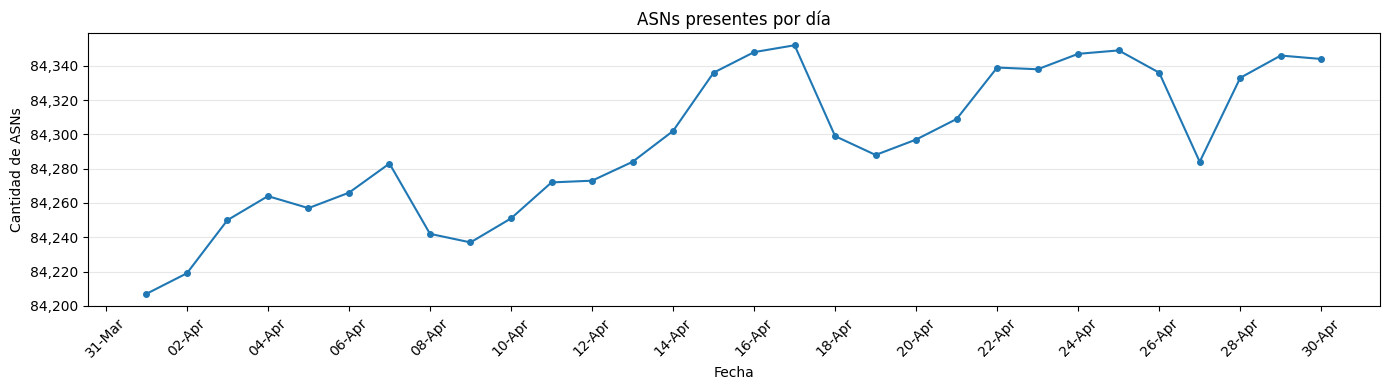

Mínimo: 84,207 (2025-04-01)
Máximo: 84,352 (2025-04-17)
Promedio: 84,295.1


In [4]:
conteo_diario = df.sum(axis=0)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(conteo_diario.index, conteo_diario.values, marker="o", markersize=4, linewidth=1.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45)
ax.set_title("ASNs presentes por día")
ax.set_ylabel("Cantidad de ASNs")
ax.set_xlabel("Fecha")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mínimo: {conteo_diario.min():,} ({conteo_diario.idxmin().date()})")
print(f"Máximo: {conteo_diario.max():,} ({conteo_diario.idxmax().date()})")
print(f"Promedio: {conteo_diario.mean():,.1f}")

## 3. Distribución de tasa de presencia

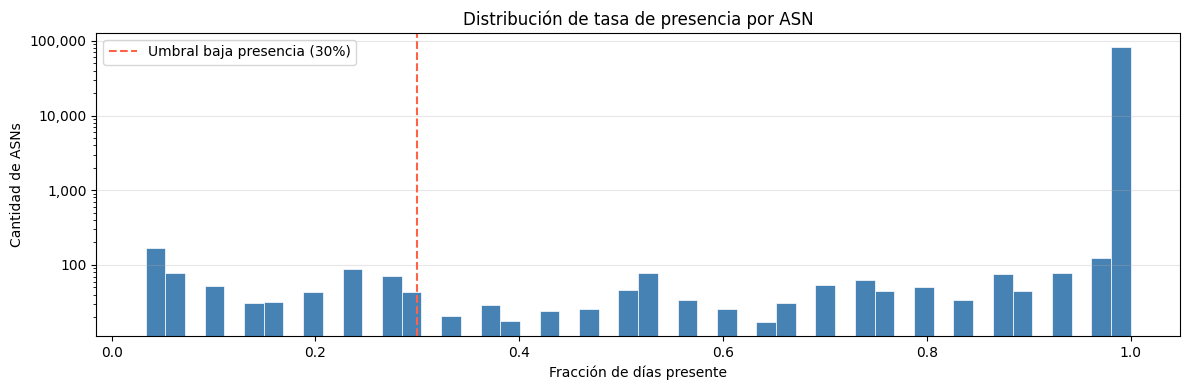

In [5]:
tasa_presencia = df.mean(axis=1)  # fracción de días en que cada ASN está presente

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(tasa_presencia, bins=50, color="steelblue", edgecolor="white", linewidth=0.5)
ax.axvline(UMBRAL_BAJA_PRESENCIA, color="tomato", linestyle="--", label=f"Umbral baja presencia ({UMBRAL_BAJA_PRESENCIA:.0%})")
ax.set_title("Distribución de tasa de presencia por ASN")
ax.set_xlabel("Fracción de días presente")
ax.set_ylabel("Cantidad de ASNs")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

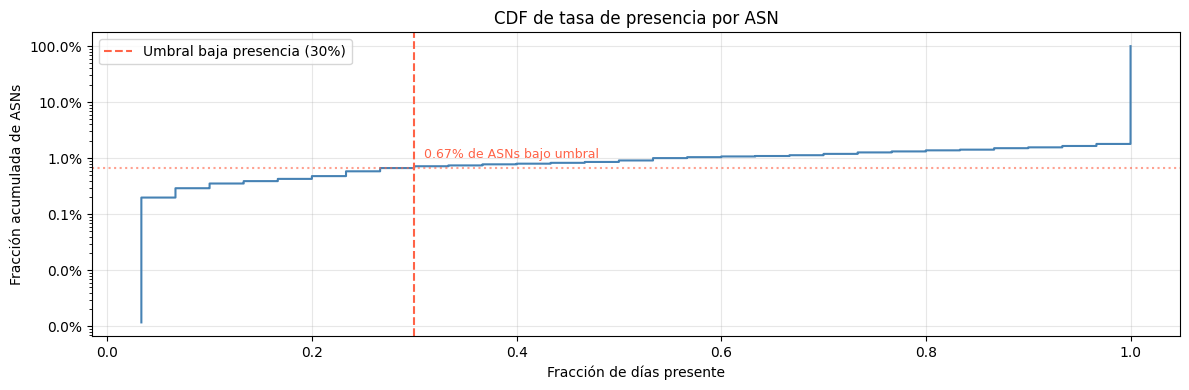

In [17]:
sorted_tasa = np.sort(tasa_presencia.values)
n = len(sorted_tasa)
ecdf_y = np.arange(1, n + 1) / n

frac_below = (tasa_presencia < UMBRAL_BAJA_PRESENCIA).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sorted_tasa, ecdf_y, color="steelblue", linewidth=1.5, drawstyle="steps-post")
ax.axvline(UMBRAL_BAJA_PRESENCIA, color="tomato", linestyle="--",
           label=f"Umbral baja presencia ({UMBRAL_BAJA_PRESENCIA:.0%})")
ax.axhline(frac_below, color="tomato", linestyle=":", alpha=0.6)
ax.annotate(f"{frac_below:.2%} de ASNs bajo umbral",
            xy=(UMBRAL_BAJA_PRESENCIA + 0.01, frac_below * 1.5),
            fontsize=9, color="tomato")
ax.set_yscale("log")
#ax.set_xscale("log")
ax.set_title("CDF de tasa de presencia por ASN")
ax.set_xlabel("Fracción de días presente")
ax.set_ylabel("Fracción acumulada de ASNs")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# ASNs con baja presencia
baja_presencia = tasa_presencia[tasa_presencia < UMBRAL_BAJA_PRESENCIA].sort_values()
print(f"ASNs con presencia < {UMBRAL_BAJA_PRESENCIA:.0%}: {len(baja_presencia):,}")

df_baja = pd.DataFrame({
    "ASN": baja_presencia.index,
    "días_presente": (baja_presencia * n_dias).astype(int).values,
    "tasa_presencia": baja_presencia.values,
})
df_baja.head(20)

ASNs con presencia < 30%: 568


,ASN,días_presente,tasa_presencia
0,11,1,0.033333
1,142078,1,0.033333
2,142079,1,0.033333
3,142080,1,0.033333
4,142081,1,0.033333
5,142082,1,0.033333
6,142083,1,0.033333
7,142084,1,0.033333
8,142085,1,0.033333
9,142086,1,0.033333


## 4. Churn diario (apariciones y desapariciones)

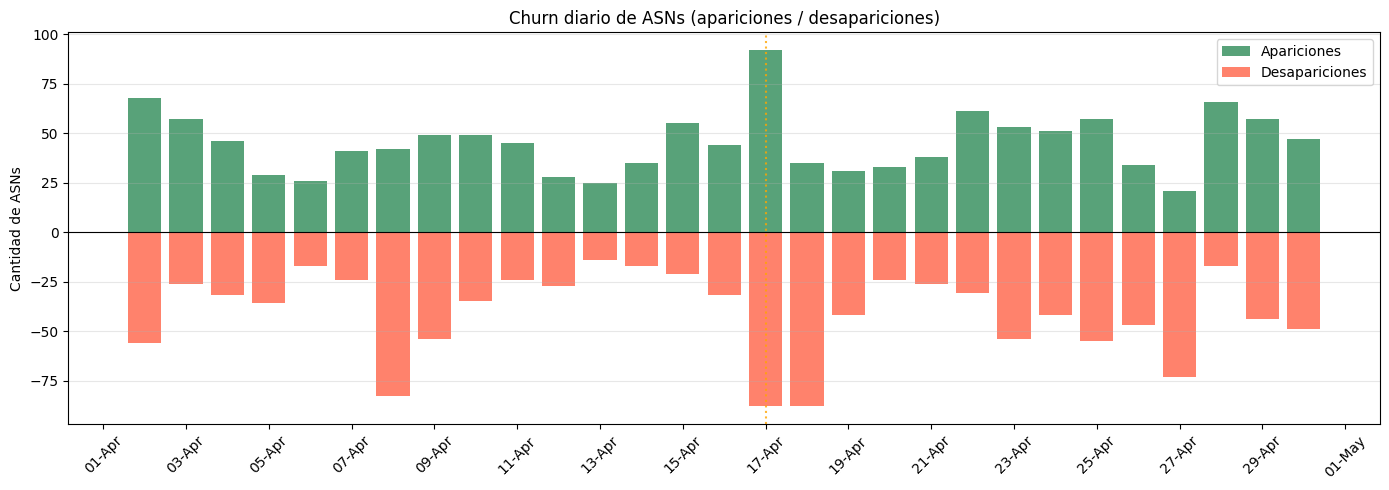

Días con churn anómalo (> media + 2.0σ = 145):
  2025-04-17  churn=180  (+92 / -88)


In [8]:
# Diferencia día a día: +1 = apareció, -1 = desapareció
diff = df.diff(axis=1).iloc[:, 1:]  # primera columna es NaN tras diff

apariciones   = (diff ==  1).sum(axis=0)
desapariciones = (diff == -1).sum(axis=0)
churn_total   = apariciones + desapariciones

media_churn = churn_total.mean()
sigma_churn = churn_total.std()
umbral_anomalia = media_churn + UMBRAL_CHURN_SIGMA * sigma_churn

dias_anomalos = churn_total[churn_total > umbral_anomalia]

fig, ax = plt.subplots(figsize=(14, 5))
fechas = apariciones.index
ax.bar(fechas, apariciones.values,  label="Apariciones",    color="seagreen",  alpha=0.8)
ax.bar(fechas, -desapariciones.values, label="Desapariciones", color="tomato", alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8)
for fecha in dias_anomalos.index:
    ax.axvline(fecha, color="orange", linestyle=":", linewidth=1.5, alpha=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45)
ax.set_title("Churn diario de ASNs (apariciones / desapariciones)")
ax.set_ylabel("Cantidad de ASNs")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

if len(dias_anomalos):
    print(f"Días con churn anómalo (> media + {UMBRAL_CHURN_SIGMA}σ = {umbral_anomalia:.0f}):")
    for fecha, val in dias_anomalos.items():
        print(f"  {fecha.date()}  churn={val:,}  (+{apariciones[fecha]:,} / -{desapariciones[fecha]:,})")
else:
    print("No se detectaron días con churn anómalo.")

## 5. Clasificación de ASNs por patrón de transiciones

Cada ASN se clasifica en una de las siguientes categorías según su secuencia de presencia a lo largo del período:

| Clase | Descripción |
|-------|-------------|
| **estable_presente** | Presente todos los días del período. No tiene ninguna transición. |
| **estable_ausente** | Ausente todos los días. Aparece en la matriz porque estaba presente en algún otro período analizado junto a éste. |
| **naciendo** | Ausente al comienzo y presente al final: una única transición 0→1 sin retorno. Puede indicar un AS recién asignado o que acaba de comenzar a anunciarse. |
| **muriendo** | Presente al comienzo y ausente al final: una única transición 1→0 sin retorno. Puede indicar un AS que dejó de anunciarse o fue retirado. |
| **renaciendo** | Tuvo al menos una desaparición y una reaparición, y su última transición fue 0→1. Volvió a estar presente al final del período. |
| **flapping** | Tiene `MIN_TRANSICIONES_FLAP` o más transiciones en total. Señal de inestabilidad: el AS aparece y desaparece repetidamente. |
| **esporádico** | Tiene transiciones pero no encaja en ninguno de los patrones anteriores. Presencia irregular sin una tendencia clara. |

In [9]:
def clasificar(fila):
    """Clasifica un ASN según su patrón de presencia."""
    vals = fila.values
    transiciones = np.diff(vals.astype(np.int8))
    n_01 = (transiciones ==  1).sum()  # 0 → 1: aparición
    n_10 = (transiciones == -1).sum()  # 1 → 0: desaparición
    total = n_01 + n_10

    if total == 0:
        return "estable_presente" if vals[0] == 1 else "estable_ausente"
    if total >= MIN_TRANSICIONES_FLAP:
        return "flapping"
    if n_01 == 1 and n_10 == 0 and vals[0] == 0:
        return "naciendo"
    if n_10 == 1 and n_01 == 0 and vals[-1] == 0:
        return "muriendo"
    if n_01 >= 1 and n_10 >= 1:
        ultima = np.where(transiciones != 0)[0][-1]
        return "renaciendo" if transiciones[ultima] == 1 else "esporádico"
    return "esporádico"

clases = df.apply(clasificar, axis=1)
conteo_clases = clases.value_counts()
print(conteo_clases.to_string())

estable_presente    83545
naciendo              574
muriendo              464
esporádico            201
renaciendo            189
flapping              102


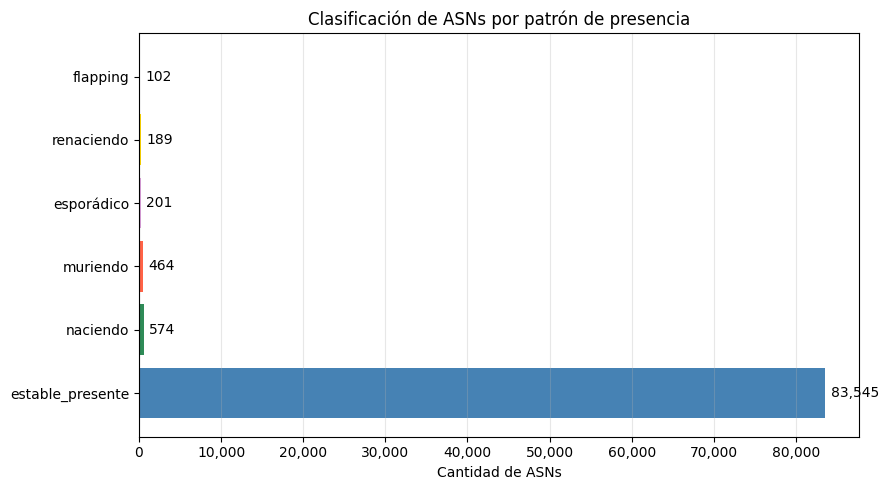

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
colores = {
    "estable_presente": "steelblue",
    "estable_ausente":  "lightsteelblue",
    "naciendo":         "seagreen",
    "muriendo":         "tomato",
    "renaciendo":       "gold",
    "flapping":         "darkorange",
    "esporádico":       "plum",
}
bars = ax.barh(
    conteo_clases.index,
    conteo_clases.values,
    color=[colores.get(c, "gray") for c in conteo_clases.index]
)
ax.bar_label(bars, fmt=lambda x: f"{int(x):,}", padding=4)
ax.set_title("Clasificación de ASNs por patrón de presencia")
ax.set_xlabel("Cantidad de ASNs")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Tablas por categoría de interés
for categoria in ["naciendo", "muriendo", "renaciendo", "flapping"]:
    asns = clases[clases == categoria].index
    if len(asns) == 0:
        continue
    print(f"\n── {categoria.upper()} ({len(asns):,} ASNs) ──")
    sub = df.loc[asns].copy()
    sub["tasa"] = tasa_presencia.loc[asns]
    sub["transiciones"] = sub.drop(columns="tasa").apply(
        lambda r: int(np.diff(r.values.astype(np.int8).__abs__()).sum()), axis=1
    )
    display(sub[["tasa", "transiciones"]].sort_values("transiciones", ascending=False).head(15))


── NACIENDO (574 ASNs) ──


,tasa,transiciones
ASN,,
914,0.533333,1
213455,0.266667,1
213196,0.100000,1
213333,0.266667,1
213377,0.700000,1
213385,0.966667,1
213441,0.433333,1
213442,0.100000,1
213461,0.700000,1



── MURIENDO (464 ASNs) ──


,tasa,transiciones
ASN,,
403,0.366667,-1
206126,0.266667,-1
209070,0.866667,-1
209051,0.300000,-1
207854,0.866667,-1
207782,0.933333,-1
207566,0.600000,-1
207532,0.733333,-1
207396,0.233333,-1



── RENACIENDO (189 ASNs) ──


,tasa,transiciones
ASN,,
408,0.700000,1
211265,0.933333,1
209935,0.133333,1
153722,0.933333,1
153656,0.566667,1
152681,0.433333,1
151388,0.500000,1
150783,0.333333,1
149156,0.233333,1



── FLAPPING (102 ASNs) ──


,tasa,transiciones
ASN,,
401350,0.200000,1
26900,0.500000,1
210969,0.433333,1
2851,0.400000,1
150528,0.366667,1
150090,0.300000,1
62039,0.766667,1
264749,0.400000,1
56393,0.200000,1


## 6. Sesgo por día de la semana

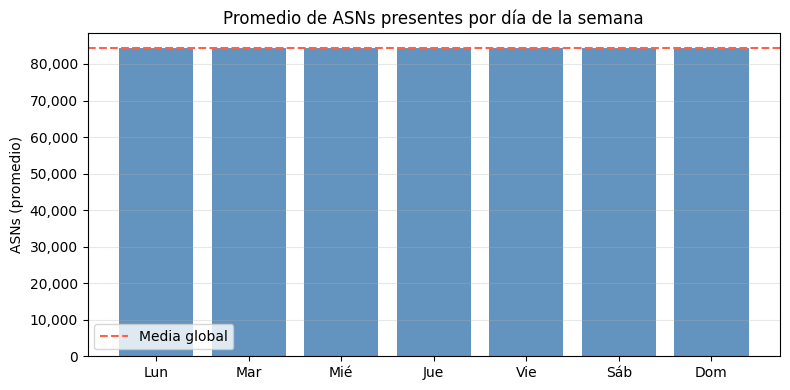

Rango inter-día: 24 ASNs  (0.03% de la media)


In [12]:
nombres_dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
conteo_por_dow = conteo_diario.copy()
conteo_por_dow.index = conteo_por_dow.index.dayofweek
media_por_dow = conteo_por_dow.groupby(level=0).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([nombres_dias[i] for i in media_por_dow.index], media_por_dow.values, color="steelblue", alpha=0.85)
ax.axhline(conteo_diario.mean(), color="tomato", linestyle="--", label="Media global")
ax.set_title("Promedio de ASNs presentes por día de la semana")
ax.set_ylabel("ASNs (promedio)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

rango = media_por_dow.max() - media_por_dow.min()
print(f"Rango inter-día: {rango:,.0f} ASNs  ({rango / conteo_diario.mean():.2%} de la media)")

## 7. Detección de twins (ASNs correlacionados)

In [13]:
# Restringir a ASNs variables (presencia < TWIN_MAX_PRESENCIA)
variables = tasa_presencia[tasa_presencia < TWIN_MAX_PRESENCIA].index
print(f"ASNs variables (presencia < {TWIN_MAX_PRESENCIA:.0%}): {len(variables):,}")

mat = df.loc[variables].values.astype(np.float32)  # shape: (n_variables, n_dias)

# Similitud de Jaccard vectorizada: |A∩B| / |A∪B|
# Para vectores binarios: intersección = dot product, unión = sum(a) + sum(b) - dot
interseccion = mat @ mat.T
presencias   = mat.sum(axis=1, keepdims=True)
union        = presencias + presencias.T - interseccion
# Evitar división por cero (ASNs nunca presentes ya están filtrados, pero por seguridad)
with np.errstate(invalid="ignore", divide="ignore"):
    jaccard = np.where(union > 0, interseccion / union, 0.0)
np.fill_diagonal(jaccard, 0)  # ignorar auto-similitud

print(f"Matriz de similitud calculada: {jaccard.shape}")

ASNs variables (presencia < 90%): 1,285
Matriz de similitud calculada: (1285, 1285)


In [14]:
# Extraer top-N pares
# Tomar sólo el triángulo superior para no duplicar pares
i_idx, j_idx = np.triu_indices(len(variables), k=1)
sims = jaccard[i_idx, j_idx]
top_idx = np.argsort(sims)[-TWIN_TOP_N:][::-1]

asns_arr = variables.to_numpy()
pares = [
    (asns_arr[i_idx[k]], asns_arr[j_idx[k]], sims[k])
    for k in top_idx
]

df_twins = pd.DataFrame(pares, columns=["ASN_A", "ASN_B", "jaccard"])
print(f"Top {TWIN_TOP_N} pares más similares:")
display(df_twins)

Top 30 pares más similares:


,ASN_A,ASN_B,jaccard
0,1096,152378,1.0
1,142085,142098,1.0
2,133589,273906,1.0
3,142085,142106,1.0
4,142085,142105,1.0
5,142085,142104,1.0
6,142085,142103,1.0
7,142085,142102,1.0
8,142085,142101,1.0
9,142085,142100,1.0


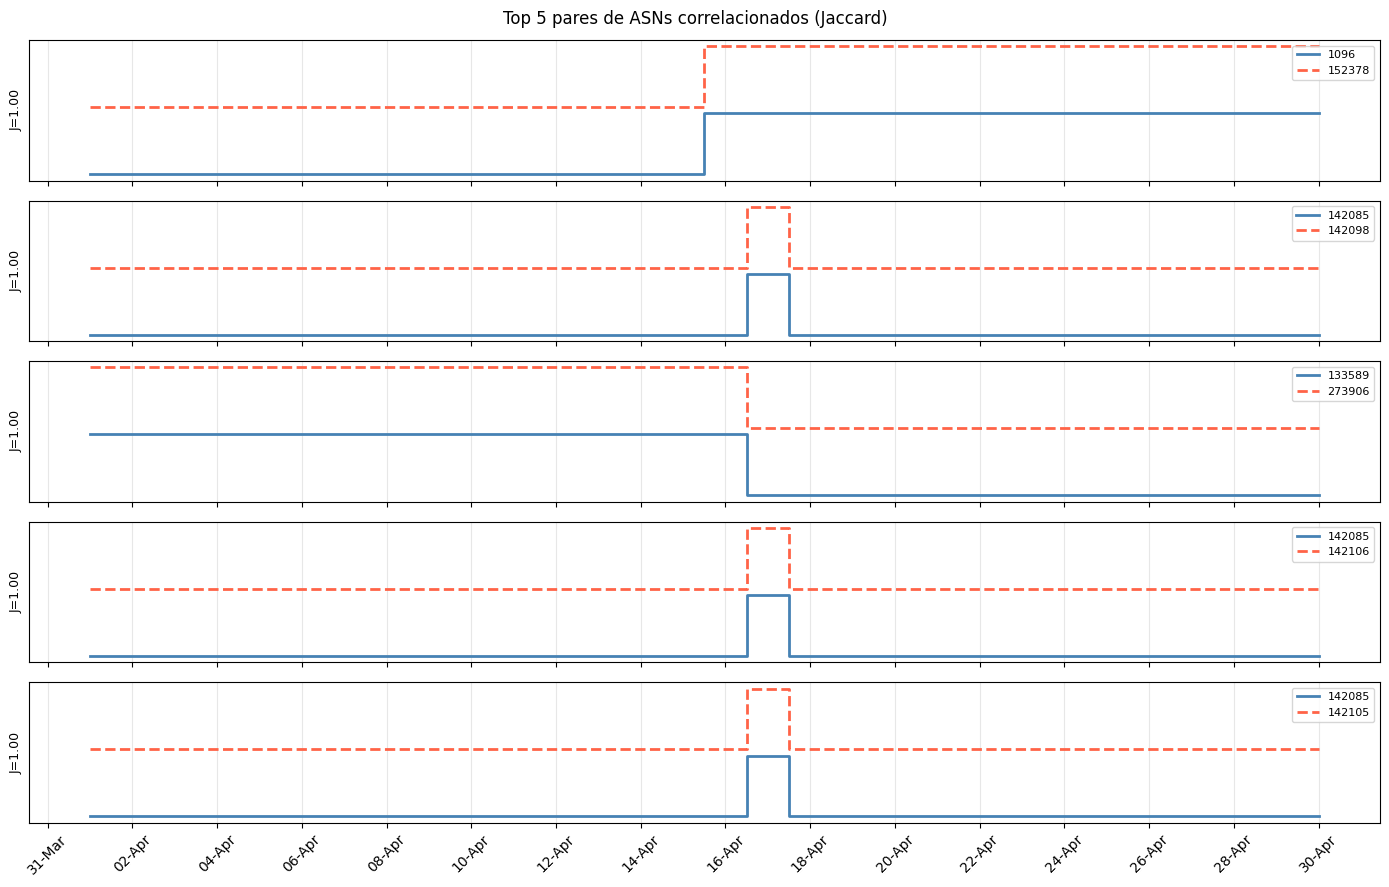

In [15]:
# Visualizar los top-5 pares lado a lado
TOP_PLOT = 5
fig, axes = plt.subplots(TOP_PLOT, 1, figsize=(14, TOP_PLOT * 1.8), sharex=True)

for ax, (asn_a, asn_b, sim) in zip(axes, pares[:TOP_PLOT]):
    fechas = df.columns
    va = df.loc[asn_a].values
    vb = df.loc[asn_b].values
    ax.step(fechas, va,       where="mid", label=f"{asn_a}", linewidth=2, color="steelblue")
    ax.step(fechas, vb + 1.1, where="mid", label=f"{asn_b}", linewidth=2, color="tomato", linestyle="--")
    ax.set_yticks([])
    ax.set_ylabel(f"J={sim:.2f}", fontsize=9)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(axis="x", alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45)
fig.suptitle(f"Top {TOP_PLOT} pares de ASNs correlacionados (Jaccard)", fontsize=12)
plt.tight_layout()
plt.show()